# Modelo de intermitencia PV + BESS

## Cuaderno reproducible, explicado y ejecutable

Este cuaderno reconstruye la lógica del proyecto a partir de los archivos de resultados generados por el pipeline. Explica el diagnóstico de factibilidad, las métricas de intermitencia $B$ y $M$, las curvas capacidad–confiabilidad, el dimensionamiento conjunto PV+BESS y el modelo sustituto $\kappa(B,M,PSH)$.

Los números no están escritos a mano: todas las tablas y figuras se leen de `resultados/`. Si se modifica `config.yaml`, se activa `RECALCULAR` más abajo y se vuelve a ejecutar el cuaderno, todo se actualiza.

## 1. Preparación

Se fija la raíz del proyecto, se configura Matplotlib para ejecución sin interfaz gráfica y se cargan las bibliotecas. La caché local evita fallos en ambientes donde la carpeta personal no es escribible.

In [2]:
from pathlib import Path
import os, subprocess, sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'config.yaml').is_file():
    candidatos = [p for p in ROOT.parents if (p / 'config.yaml').is_file()]
    if not candidatos:
        raise FileNotFoundError('Ejecuta el cuaderno dentro del proyecto Modelo intermitencia')
    ROOT = candidatos[0]

os.environ.setdefault('MPLBACKEND', 'Agg')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))
(ROOT / '.cache' / 'matplotlib').mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from intermitencia import Config

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
cfg = Config.cargar(ROOT / 'config.yaml')
print(f'Proyecto: {cfg.nombre}')
print(f'Raíz: {ROOT}')

Proyecto: Dimensionamiento PV+BESS con métricas de intermitencia
Raíz: C:\Users\Melissa\Downloads\TESIS\tesisMeli-main (1)\tesisMeli-main


## 2. Reproducibilidad del flujo

El flujo tiene siete pasos dependientes: diagnóstico → intermitencia → curvas → óptimo 2-D → sustituto → figuras → informe PDF. Por defecto el cuaderno reutiliza la ejecución verificada para abrir rápido. Cambie `RECALCULAR = True` cuando modifique datos o supuestos; esa opción ejecuta pruebas y los siete pasos desde los insumos crudos.

In [3]:
RECALCULAR = False

if RECALCULAR:
    proceso = subprocess.run(
        [str(ROOT / 'run_todo.sh')], cwd=ROOT, text=True,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, check=True
    )
    print(proceso.stdout)
else:
    prueba = subprocess.run(
        [sys.executable, '-m', 'pytest', 'tests/', '-q'], cwd=ROOT,
        text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, check=True
    )
    print(prueba.stdout.strip())
    print('Se usan los resultados ya calculados. Active RECALCULAR para regenerarlos.')

...............................                                          [100%]
31 passed in 10.53s
Se usan los resultados ya calculados. Active RECALCULAR para regenerarlos.


### Supuestos principales

La demanda es plana. La potencia FV se calcula como $P(t)=P_{PV}(GHI/1000)PR$. El BESS incluye límites de potencia, eficiencias de carga y descarga, ventana de SOC, vertimiento y ciclos. Los valores económicos siguen marcados como **REVISAR**: sirven para explorar el método, pero no deben publicarse hasta sustituirlos por fuentes citables.

In [4]:
parametros = pd.DataFrame([
    ('Demanda plana', cfg.demanda_mw, 'MW'),
    ('Planta inicial', cfg.planta.potencia_mw, 'MW'),
    ('Performance ratio', cfg.planta.performance_ratio, '-'),
    ('Duración BESS', cfg.bess.duracion_h, 'h'),
    ('Eficiencia round-trip', cfg.bess.eff_roundtrip, '-'),
    ('SOC mínimo', cfg.bess.soc_min_frac, '-'),
    ('VoLL (REVISAR)', cfg.economia.voll_usd_mwh, 'USD/MWh'),
    ('WACC (REVISAR)', cfg.economia.tasa_descuento, '-'),
], columns=['Parámetro', 'Valor', 'Unidad'])
display(parametros)

,Parámetro,Valor,Unidad
0,Demanda plana,20.000,MW
1,Planta inicial,100.000,MW
2,Performance ratio,0.800,-
3,Duración BESS,4.000,h
4,Eficiencia round-trip,0.902,-
5,SOC mínimo,0.100,-
6,VoLL (REVISAR),600.000,USD/MWh
7,WACC (REVISAR),0.100,-


## 3. Carga de resultados

Cada archivo corresponde a una pregunta concreta. Se valida su existencia antes de continuar para impedir que un cuaderno parcialmente ejecutado muestre conclusiones antiguas como si fueran actuales.

In [5]:
salida = cfg.rutas.salida
archivos = {
    'diag': '01_diagnostico_series.xlsx',
    'intermitencia': '02_intermitencia.xlsx',
    'comparacion': '02_comparacion_metodos.xlsx',
    'curvas': '03_curvas.xlsx',
    'interanual': '03_interanual.xlsx',
    'optimos': '04_optimos.xlsx',
    'grilla': '04_grilla.xlsx',
    'pareto': '04_pareto.xlsx',
    'kappa': '05_kappa.xlsx',
    'coef': '05_sustituto_coeficientes.xlsx',
}
faltantes = [nombre for nombre in archivos.values() if not (salida / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan resultados: {faltantes}. Active RECALCULAR.')

diag = pd.read_excel(salida / archivos['diag']).set_index('Serie')
bm = pd.read_excel(salida / archivos['comparacion']).set_index('Serie')
curvas = pd.read_excel(salida / archivos['curvas'])
interanual = pd.read_excel(salida / archivos['interanual']).set_index('Serie')
optimos = pd.read_excel(salida / archivos['optimos']).set_index('Serie')
pareto = pd.read_excel(salida / archivos['pareto'])
kappa = pd.read_excel(salida / archivos['kappa']).set_index('Serie')
coef = pd.read_excel(salida / archivos['coef']).set_index('index')['valor']
print(f'{len(diag)} series y {len(curvas):,} puntos de curvas cargados.')

FileNotFoundError: Faltan resultados: ['01_diagnostico_series.xlsx', '02_intermitencia.xlsx', '02_comparacion_metodos.xlsx', '03_curvas.xlsx', '03_interanual.xlsx', '04_optimos.xlsx', '04_grilla.xlsx', '04_pareto.xlsx', '05_kappa.xlsx', '05_sustituto_coeficientes.xlsx']. Active RECALCULAR.

## 4. Diagnóstico de factibilidad energética

Antes de dimensionar almacenamiento hay que verificar el balance medio. Si la generación media es menor que la demanda, ninguna batería puede alcanzar alta confiabilidad: el almacenamiento desplaza energía, no la crea. Esa comprobación faltaba en el modelo anterior.

In [5]:
gen = diag['gen_media_MW']
resumen_factibilidad = pd.DataFrame({
    'Valor': [gen.min(), gen.median(), gen.max(), cfg.demanda_mw,
              (gen < cfg.demanda_mw).sum(), (cfg.demanda_mw / diag['factor_planta']).median()],
    'Unidad': ['MW', 'MW', 'MW', 'MW', f'de {len(gen)} series', 'MW'],
}, index=['Generación mínima', 'Generación mediana', 'Generación máxima',
          'Demanda', 'Series deficitarias', 'Planta para equilibrio medio'])
display(resumen_factibilidad)
display(diag[['PSH_h_dia', 'gen_media_MW', 'factor_planta', 'frac_horas_deficit']]
        .sort_values('gen_media_MW').head(8))

,Valor,Unidad
Generación mínima,13.885,MW
Generación mediana,17.465,MW
Generación máxima,19.430,MW
Demanda,20.000,MW
Series deficitarias,51.000,de 51 series
Planta para equilibrio medio,114.515,MW


,PSH_h_dia,gen_media_MW,factor_planta,frac_horas_deficit
Serie,,,,
La Reforma,4.170,13.885,0.139,0.716
La Enea,4.350,14.508,0.145,0.696
Chivor,4.390,14.619,0.146,0.710
La Hermosa,4.430,14.781,0.148,0.696
Jamondino,4.480,14.924,0.149,0.689
Akacías,4.550,15.181,0.152,0.703
Panamericana,4.580,15.260,0.153,0.688
Torca,4.620,15.390,0.154,0.682


**Resultado:** las 51 series generan menos de 20 MW en promedio con una planta nominal de 100 MW y PR = 0.80. Por eso el problema correcto es bidimensional: hay que elegir simultáneamente potencia FV y capacidad BESS. Con planta fija, las curvas siguientes se aplanan porque falta energía anual.

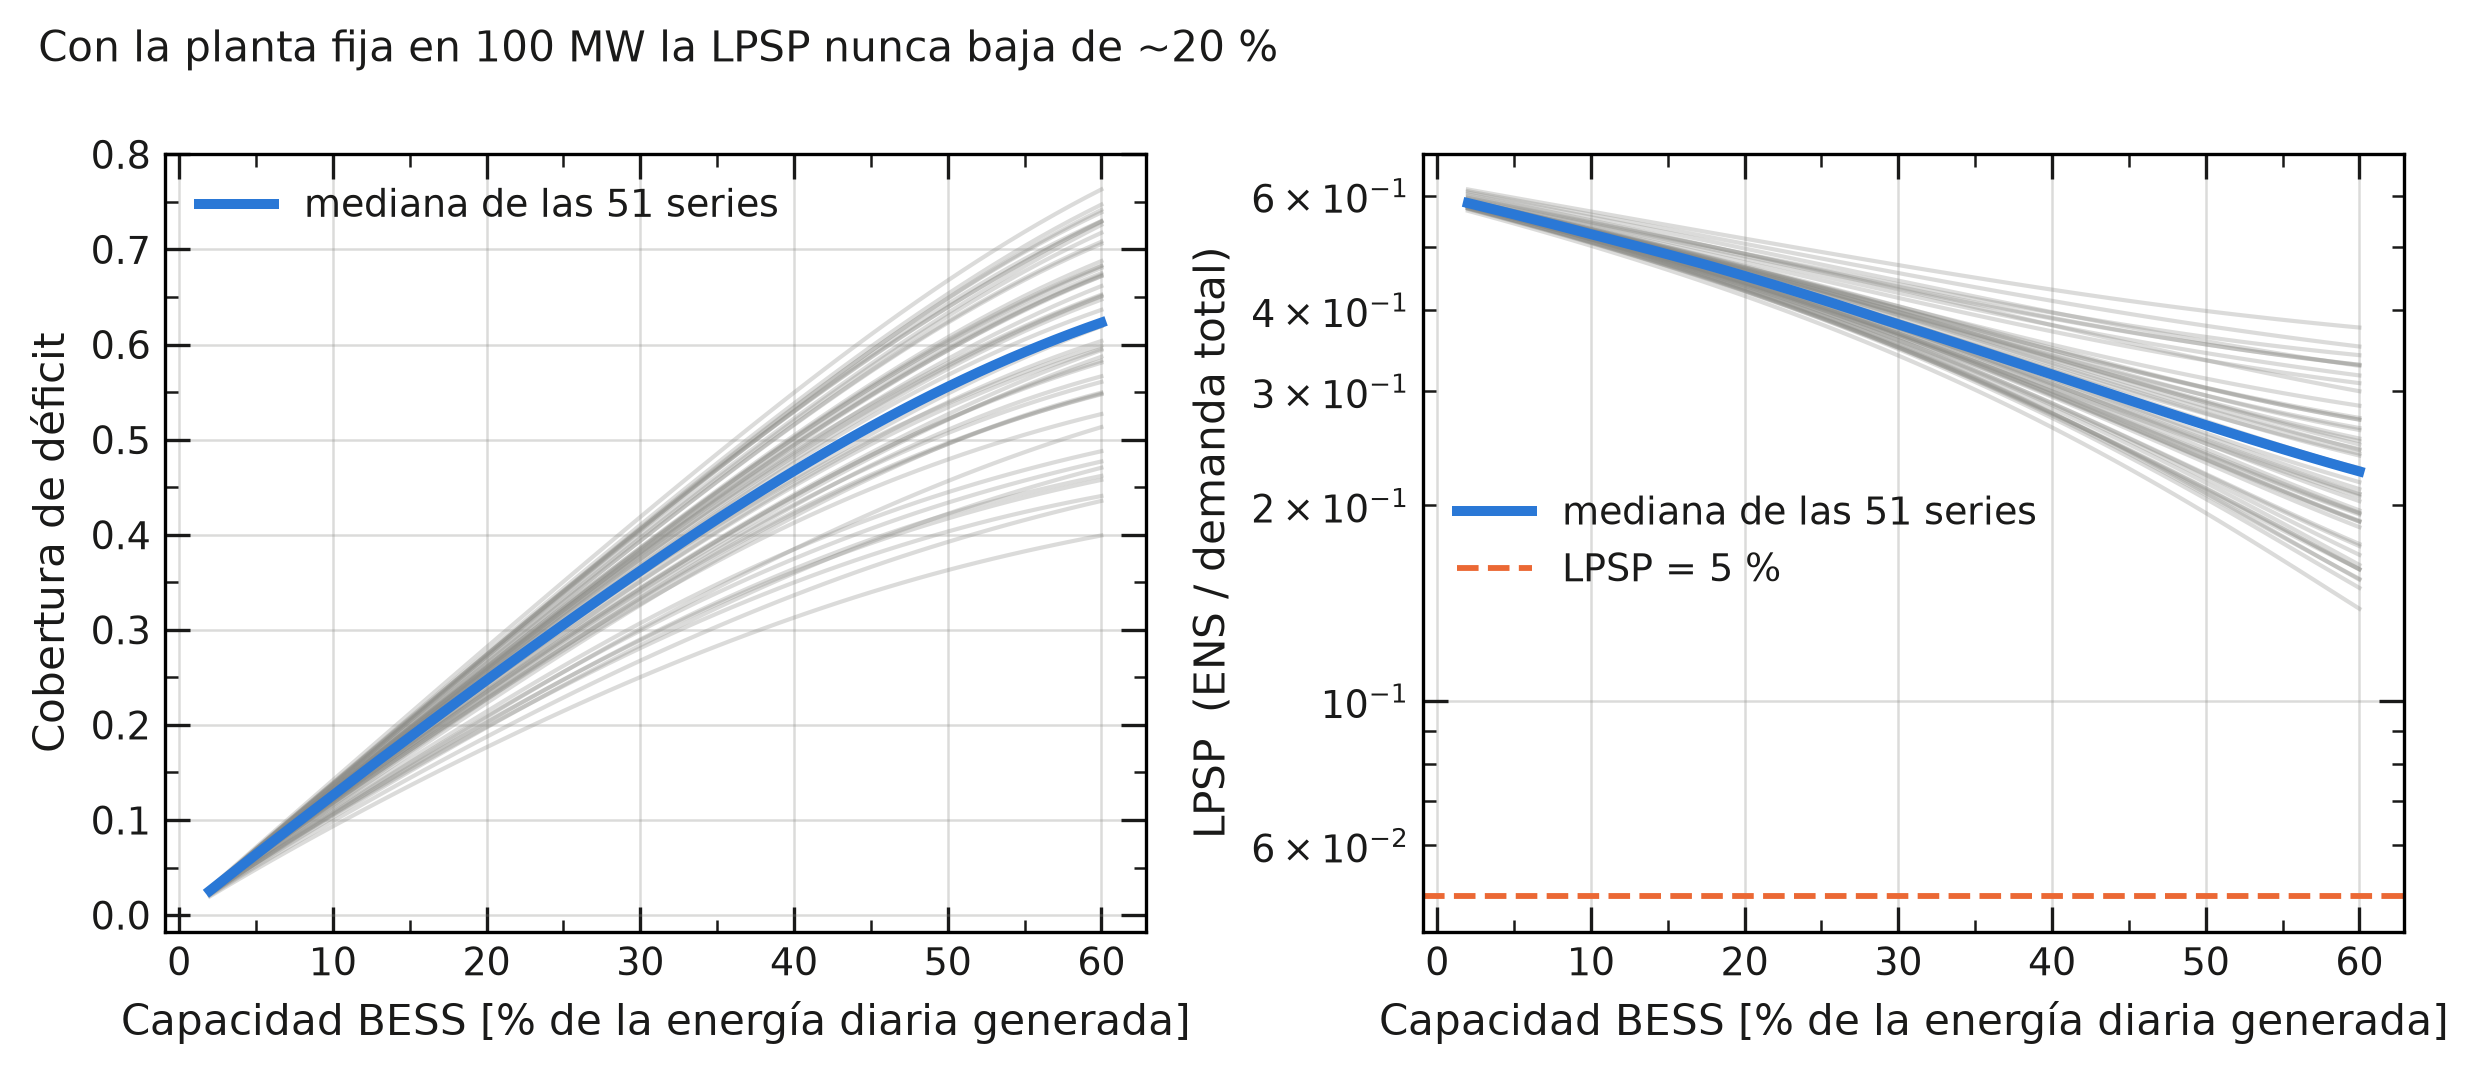

In [6]:
display(Image(filename=str(cfg.rutas.figuras / 'F2_curvas_confiabilidad.png'), width=900))

## 5. Corrección de las métricas de intermitencia

El método antiguo aplicaba burstiness a cruces de una suma acumulada monótona. Un mismo paso podía cruzar varios umbrales y crear intervalos $\tau=0$, sin significado físico. El método corregido define eventos como corridas contiguas de déficit y calcula: $B$ con corrección de tamaño finito de Kim–Jo y $M$ como correlación entre intervalos consecutivos.

,Método anterior,Método corregido
B media,0.067,-0.509
M media,-0.312,0.117
Fracción de tau=0,0.490,0.000


Correlación entre métodos: B=+0.909; M=-0.635
M cambia de signo en 47 de 51 series.


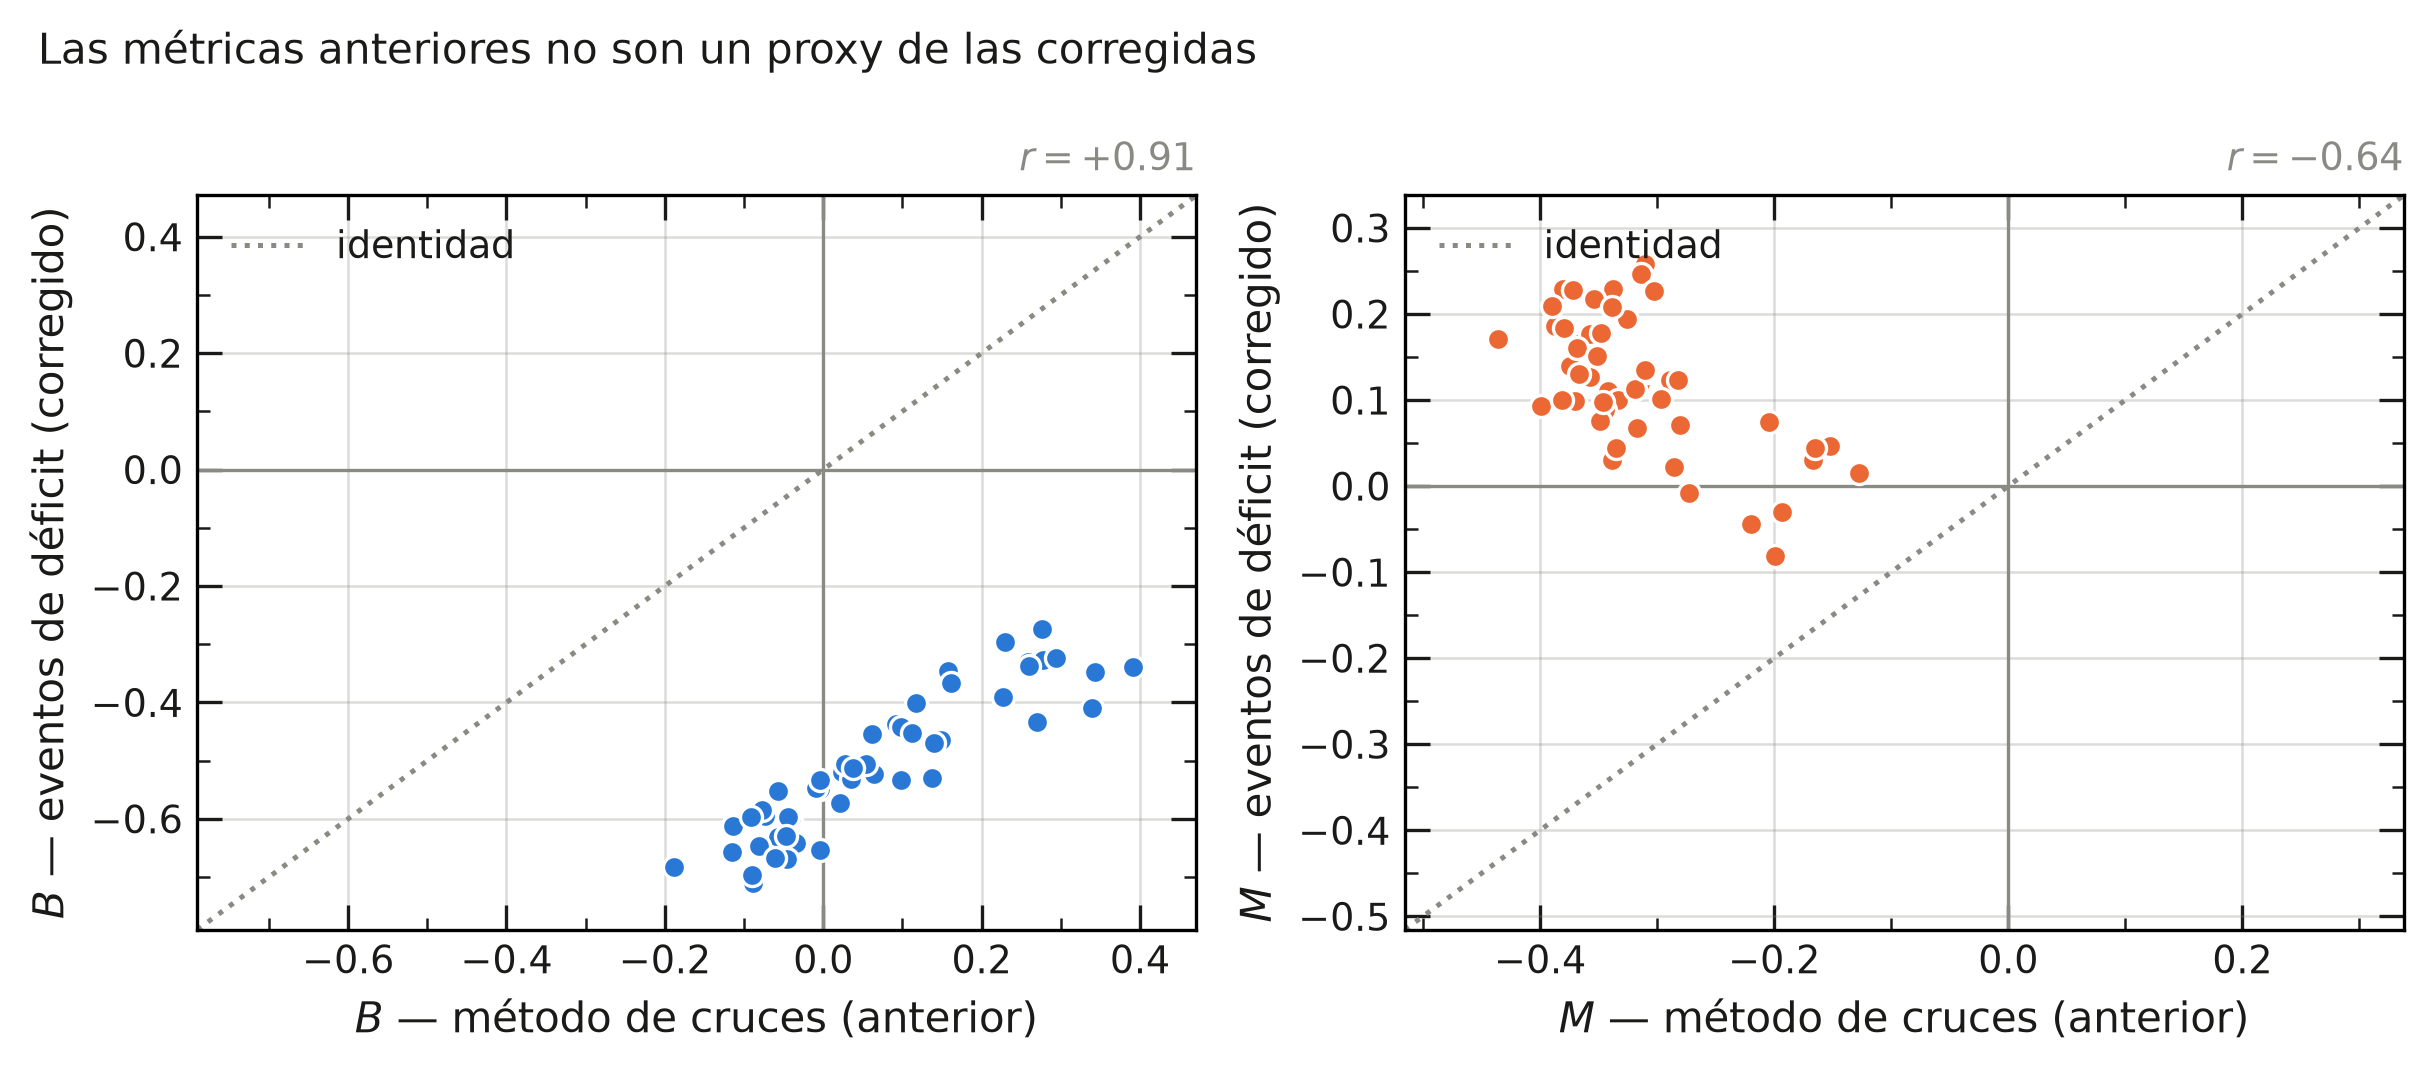

In [7]:
comparacion_bm = pd.DataFrame({
    'Método anterior': [bm.B_legacy.mean(), bm.M_legacy.mean(), bm.frac_tau_cero_legacy.mean()],
    'Método corregido': [bm.B.mean(), bm.M.mean(), 0.0],
}, index=['B media', 'M media', 'Fracción de tau=0'])
display(comparacion_bm)
print(f"Correlación entre métodos: B={bm.B.corr(bm.B_legacy):+.3f}; M={bm.M.corr(bm.M_legacy):+.3f}")
print(f"M cambia de signo en {(np.sign(bm.M) != np.sign(bm.M_legacy)).sum()} de {len(bm)} series.")
display(Image(filename=str(cfg.rutas.figuras / 'F1_comparacion_metodos_BM.png'), width=900))

## 6. Confiabilidad y variabilidad interanual

Se reportan dos métricas distintas: `lpsp = ENS / demanda total` (definición estándar) y `cobertura_deficit = 1 - ENS / energía de déficit` (continuidad con el indicador antiguo). No deben llamarse igual ni compararse directamente.

In [8]:
techo = curvas.groupby('Serie').agg(lpsp_min=('lpsp', 'min'), cobertura_max=('cobertura_deficit', 'max'))
display(techo.describe(percentiles=[.1, .5, .9]).loc[['min', '10%', '50%', '90%', 'max']])
display(pd.DataFrame({
    'mediana': interanual.median(numeric_only=True),
    'máximo': interanual.max(numeric_only=True),
}).loc[['lpsp_p50', 'lpsp_p90', 'lpsp_peor', 'razon_peor_vs_mediana']])

,lpsp_min,cobertura_max
min,0.139,0.399
10%,0.160,0.470
50%,0.226,0.623
90%,0.328,0.730
max,0.376,0.763


,mediana,máximo
lpsp_p50,0.415,0.492
lpsp_p90,0.422,0.502
lpsp_peor,0.426,0.508
razon_peor_vs_mediana,1.030,1.050


La LPSP mínima mediana con la planta fija permanece cerca de 23 %. La dispersión interanual parece pequeña porque el sistema ya está saturado por falta estructural de energía; con una planta bien dimensionada, clasificar años por ENSO será más informativo.

## 7. Óptimo económico conjunto PV + BESS

Maximizar confiabilidad sin costos siempre conduce a capacidades crecientes. El pipeline minimiza el costo anual equivalente más la energía no suministrada valorizada con VoLL sobre una grilla 2-D, seguida de refinamiento local. Así el tamaño de planta y de batería se resuelven juntos.

In [9]:
cols_opt = ['p_pv_mw', 'e_bess_mwh', 'bess_horas_de_demanda',
            'bess_pct_energia_diaria', 'lcoe_usd_mwh', 'lpsp', 'frac_vertida']
resumen_opt = pd.DataFrame({
    'p10': optimos[cols_opt].quantile(.10),
    'mediana': optimos[cols_opt].median(),
    'p90': optimos[cols_opt].quantile(.90),
})
display(resumen_opt)
print(f"Convergieron {int(optimos.convergio.sum())} de {len(optimos)} series.")

,p10,mediana,p90
p_pv_mw,135.039,151.160,179.441
e_bess_mwh,330.642,334.674,338.920
bess_horas_de_demanda,16.532,16.734,16.946
bess_pct_energia_diaria,51.393,53.262,54.996
lcoe_usd_mwh,227.201,240.351,269.797
lpsp,0.025,0.028,0.039
frac_vertida,0.186,0.214,0.247


Convergieron 51 de 51 series.


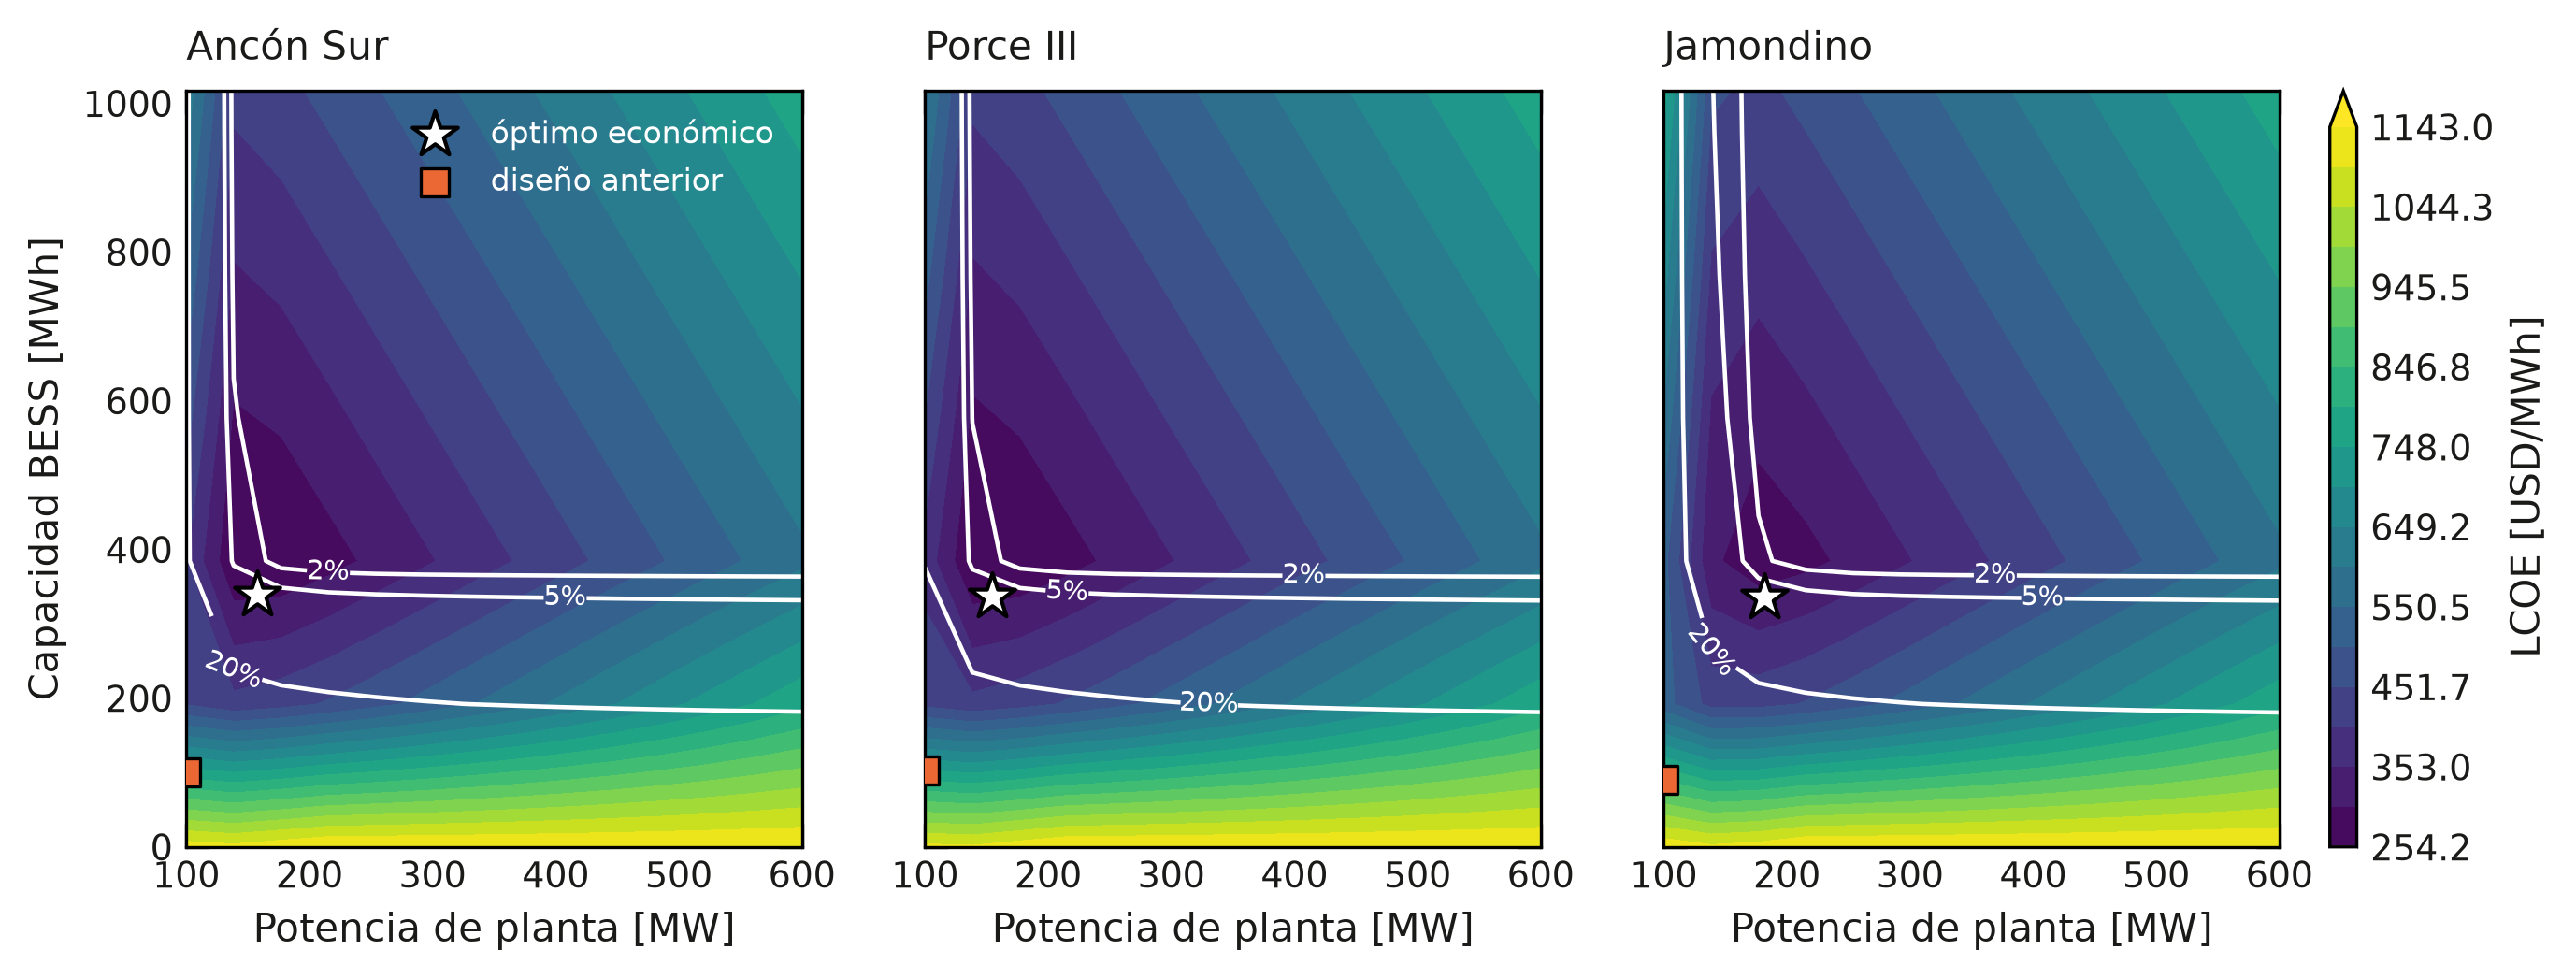

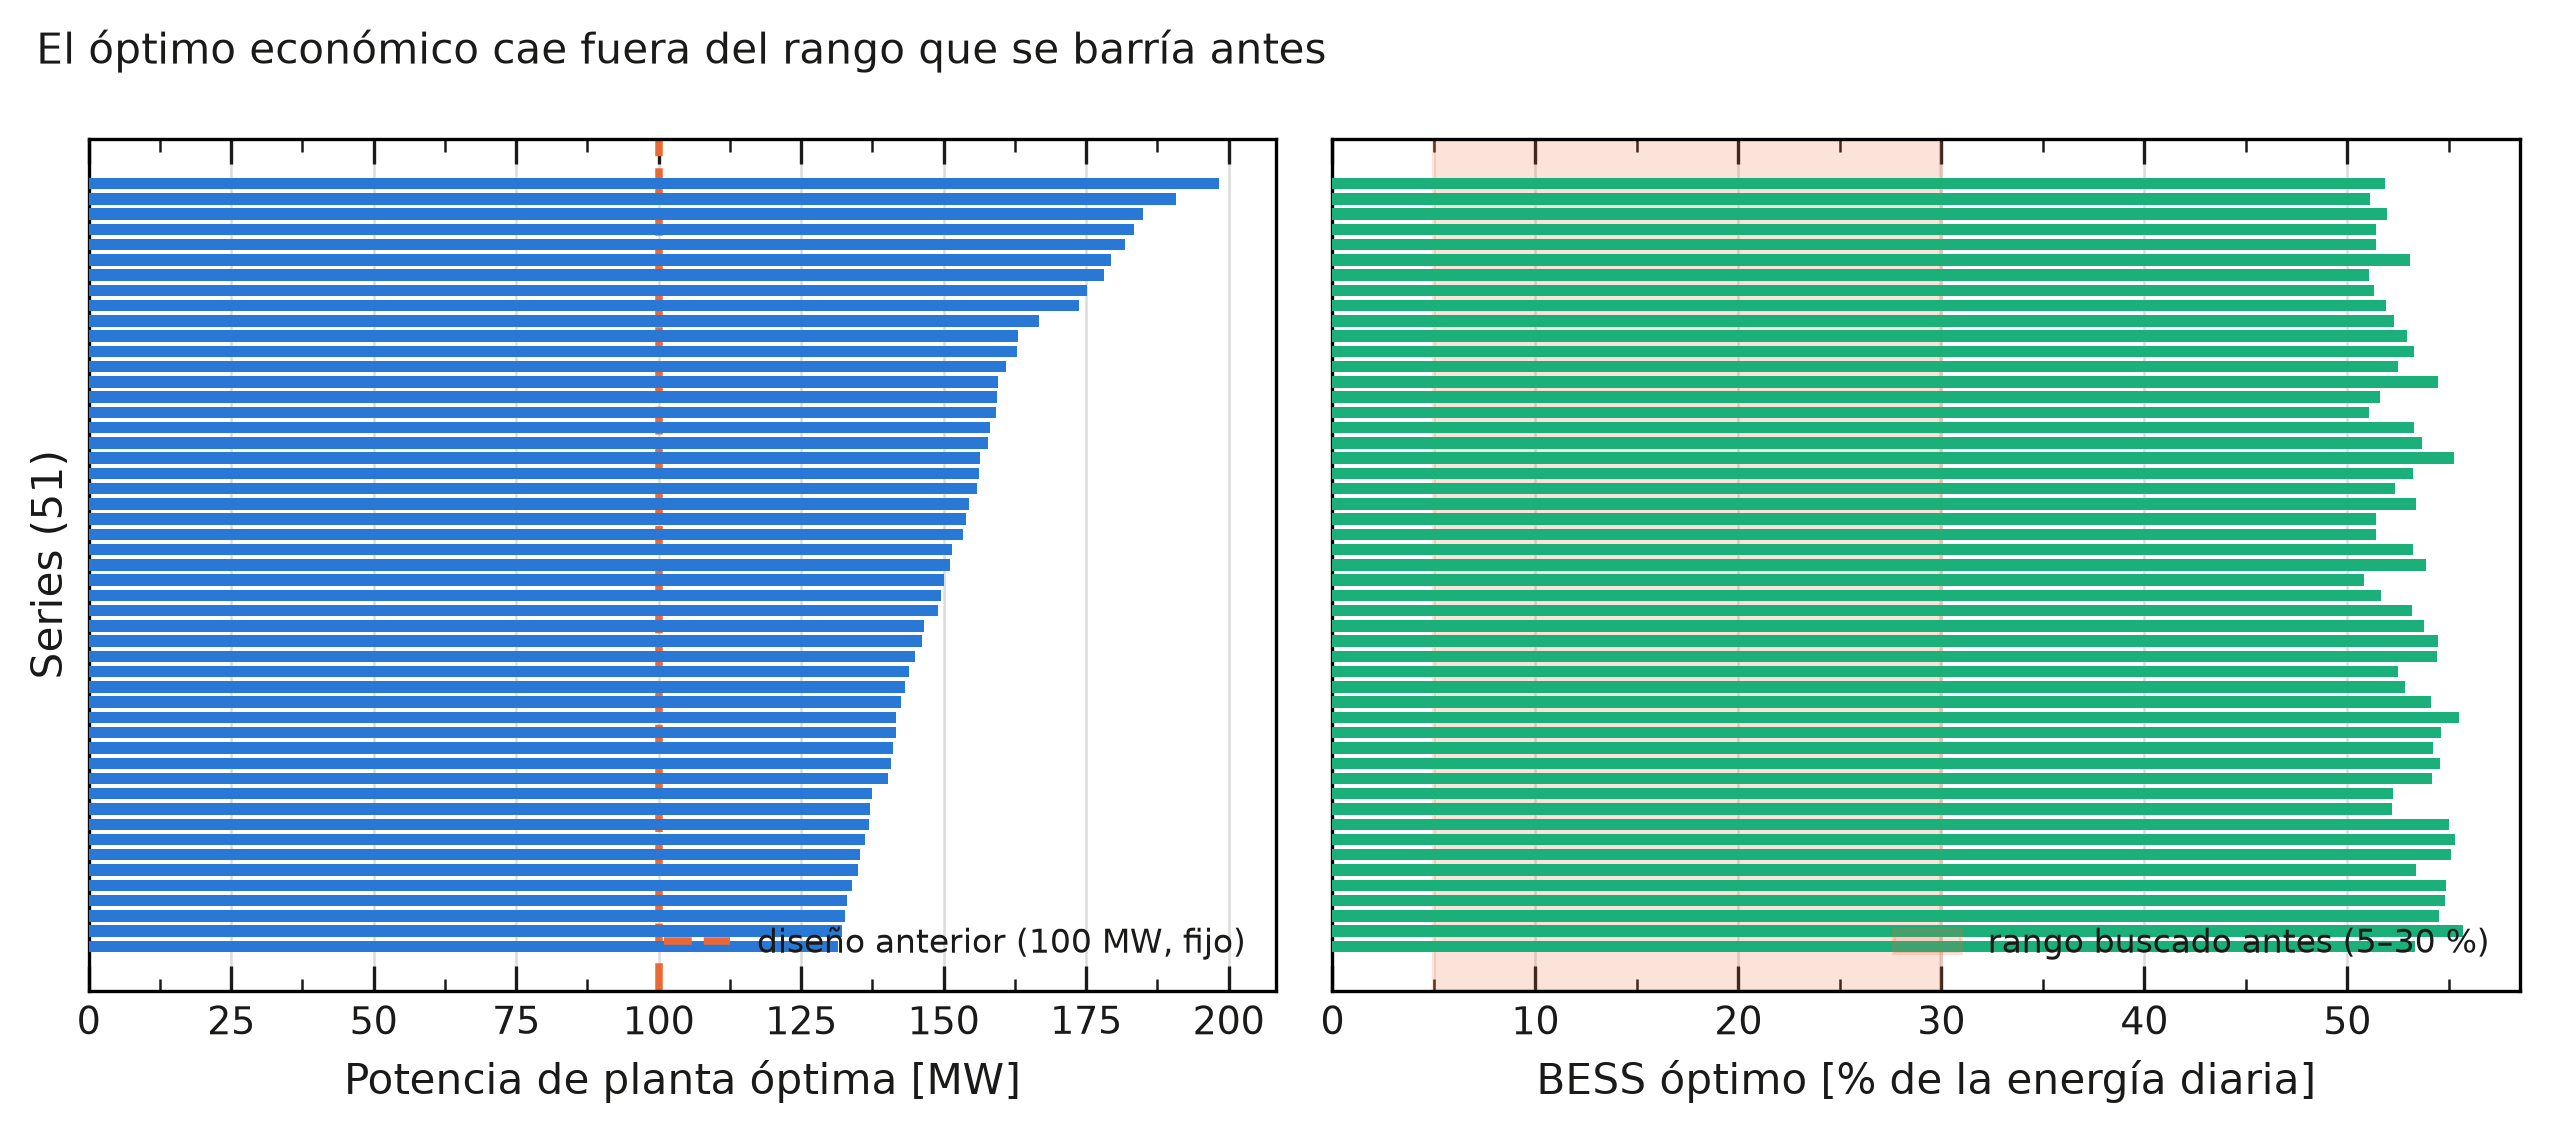

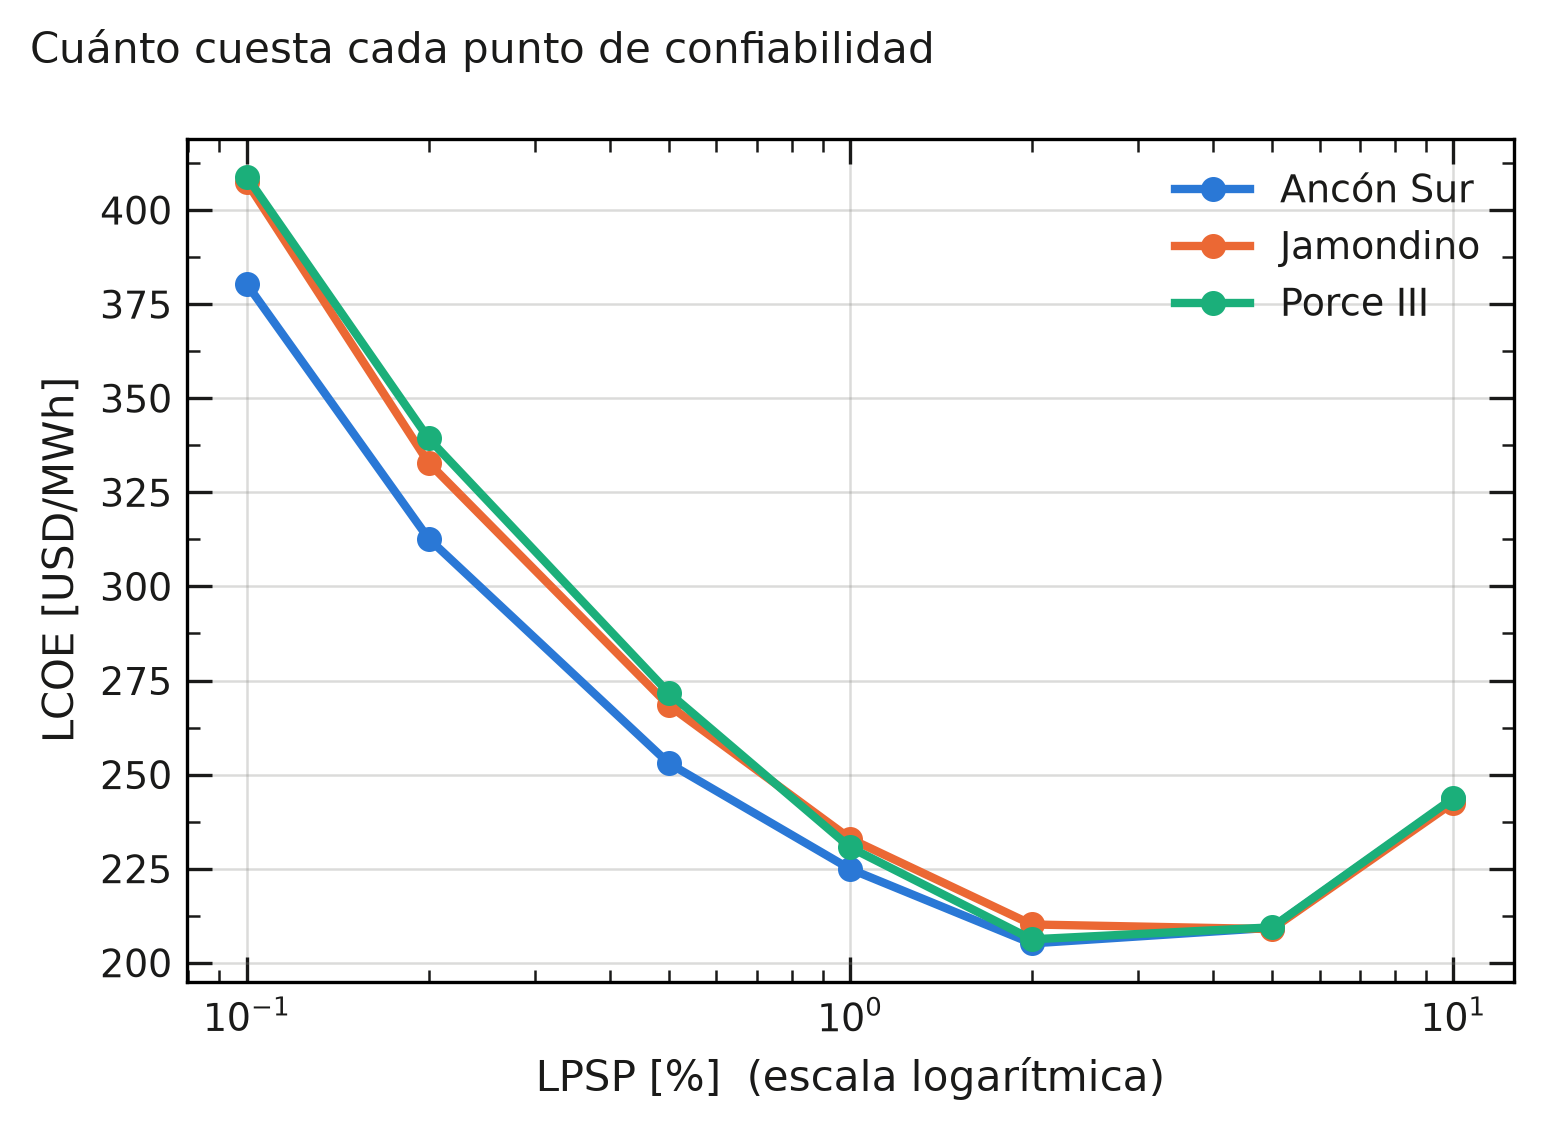

In [10]:
display(Image(filename=str(cfg.rutas.figuras / 'F3_mapa_lcoe_planta_bateria.png'), width=950))
display(Image(filename=str(cfg.rutas.figuras / 'F6_optimos_por_serie.png'), width=900))
display(Image(filename=str(cfg.rutas.figuras / 'F7_pareto_costo_confiabilidad.png'), width=900))

**Lectura principal:** la mediana del óptimo es aproximadamente 151 MW PV y 335 MWh BESS (16.7 horas de demanda), con LPSP cercana a 2.8 %. La batería equivale a cerca de 53 % de la energía diaria: queda completamente fuera del antiguo barrido de 5–30 %. Estas cifras dependen de costos todavía provisionales.

## 8. Ley exponencial y modelo sustituto

A potencia FV común de 150 MW, las curvas se aproximan por $LPSP(E) \approx L_0\exp(-E/\kappa)$. El parámetro $\kappa$ es la energía adicional que divide la LPSP por $e$. Después se ajusta $\ln\kappa$ con $B$, $M$ y PSH y se valida dejando una serie fuera en cada iteración (LOO).

In [11]:
ecuacion = (f"ln κ = {coef['intercepto']:.4f} "
            f"{coef['B']:+.4f}·B {coef['M']:+.4f}·M {coef['PSH']:+.4f}·PSH")
display(Markdown(f'### {ecuacion}'))
metricas_modelo = pd.Series({
    'R² mediano de la ley exponencial': kappa.r2_ley_exponencial.median(),
    'κ mediana [MWh]': kappa.kappa_mwh.median(),
    'R² LOO': coef['r2_loo'],
    'RMSE LOO [ln κ]': coef['rmse_loo'],
    'Mejora frente a predecir la media': coef['mejora_sobre_baseline'],
})
display(metricas_modelo.to_frame('Valor'))
display(kappa[['B', 'M', 'PSH', 'kappa_mwh', 'r2_ley_exponencial']].sort_values('kappa_mwh').head(10))

### ln κ = 11.8023 +0.3842·B +0.4837·M -1.2533·PSH

,Valor
R² mediano de la ley exponencial,0.921
κ mediana [MWh],184.248
R² LOO,0.709
RMSE LOO [ln κ],0.337
Mejora frente a predecir la media,0.471


,B,M,PSH,kappa_mwh,r2_ley_exponencial
Serie,,,,,
Primavera,-0.710,0.258,5.710,69.445,0.967
La Sierra,-0.696,0.227,5.760,74.002,0.964
Purnio,-0.630,0.194,5.620,83.015,0.963
La Virginia,-0.523,0.068,5.420,83.132,0.975
Fundación,-0.683,0.113,5.710,85.703,0.934
Brisas,-0.548,0.170,5.340,85.705,0.978
Comuneros,-0.669,0.229,5.550,87.947,0.950
Chinú,-0.599,0.139,5.480,89.726,0.970
El Copey,-0.647,0.101,5.650,90.606,0.921


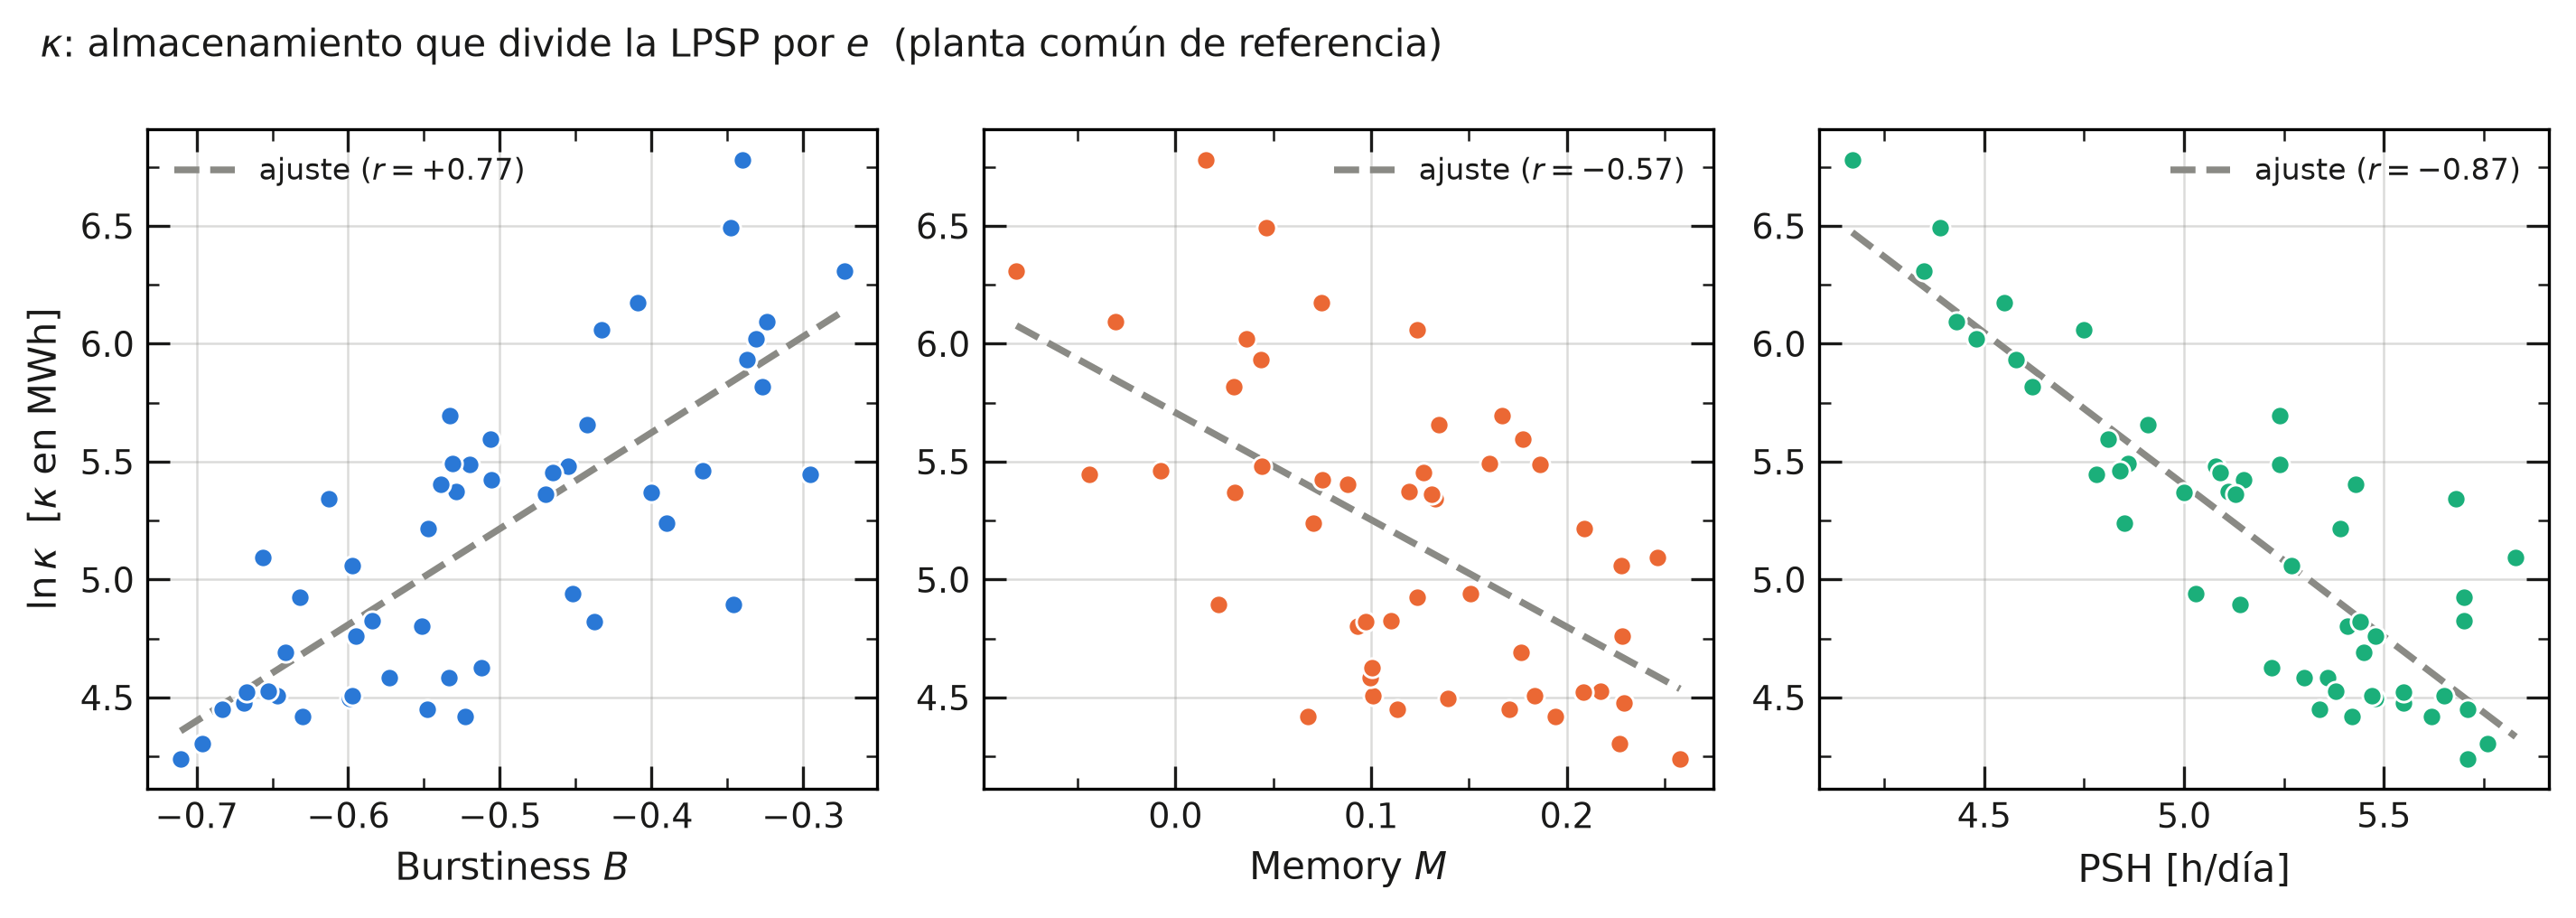

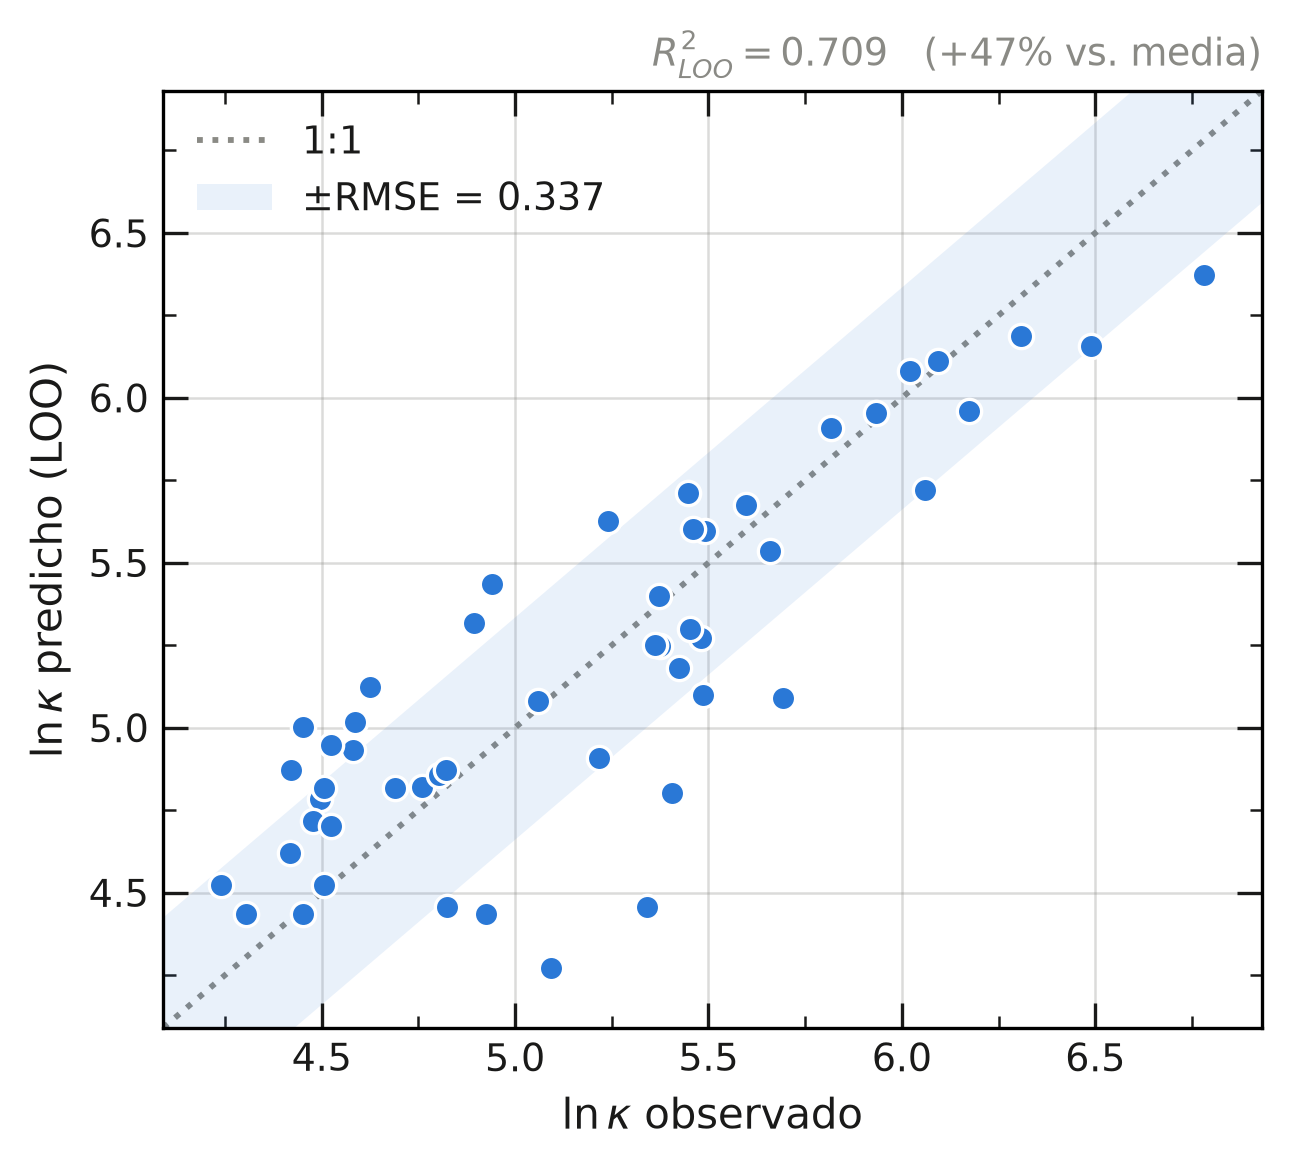

In [12]:
display(Image(filename=str(cfg.rutas.figuras / 'F4_kappa_vs_intermitencia.png'), width=950))
display(Image(filename=str(cfg.rutas.figuras / 'F5_validacion_loo.png'), width=550))

La aproximación exponencial es útil pero no exacta (R² mediano ≈ 0.92). El sustituto obtiene R² LOO ≈ 0.71 y mejora el RMSE alrededor de 47 % frente a predecir siempre la media. Debe usarse únicamente dentro de los rangos observados. A la planta óptima propia de cada sitio la señal desaparece, porque sobredimensionar la planta sustituye parcialmente al almacenamiento; una potencia común es necesaria para aislar intermitencia.

## 9. Conclusiones, límites y trabajo pendiente

1. La formulación antigua con 100 MW fijos era energéticamente inviable para una demanda plana de 20 MW.
2. Las métricas anteriores de $B$ y $M$ contenían intervalos nulos; $M$ cambia de signo en la mayoría de las series al corregirla.
3. El óptimo debe resolverse en dos dimensiones y queda fuera del rango antiguo de batería.
4. La intermitencia sí contiene señal predictiva sobre almacenamiento cuando los sitios se comparan a planta común.
5. Los costos y el VoLL de `config.yaml` son provisionales: deben sustituirse por fuentes citables antes de publicar LCOE o tamaños óptimos.
6. Faltan la aplicación a las cinco zonas, la clasificación ENSO/ONI y, si se requiere mayor precisión, evaluar una exponencial estirada.

In [13]:
entregables = [ROOT / 'Modelo_intermitencia_explicado.ipynb',
               salida / 'Informe_intermitencia.pdf']
entregables += sorted(cfg.rutas.figuras.glob('F*.png'))
pd.DataFrame({
    'Archivo': [str(p.relative_to(ROOT)) for p in entregables],
    'Existe': [p.is_file() for p in entregables],
    'Tamaño [KB]': [round(p.stat().st_size / 1024, 1) if p.is_file() else np.nan for p in entregables],
})

,Archivo,Existe,Tamaño [KB]
0,Modelo_intermitencia_explicado.ipynb,True,20.700
1,resultados/Informe_intermitencia.pdf,True,"1,694.900"
2,resultados/figuras/F1_comparacion_metodos_BM.png,True,199.400
3,resultados/figuras/F2_curvas_confiabilidad.png,True,439.900
4,resultados/figuras/F3_mapa_lcoe_planta_bateria...,True,251.800
5,resultados/figuras/F4_kappa_vs_intermitencia.png,True,197.600
6,resultados/figuras/F5_validacion_loo.png,True,112.700
7,resultados/figuras/F6_optimos_por_serie.png,True,98.600
8,resultados/figuras/F7_pareto_costo_confiabilid...,True,133.300
